# Customer Churn Prediction Using Machine Learning

**Dataset:** WA_Fn-UseC_-Telco-Customer-Churn.csv (Telco Customer Churn dataset)

**Objective:** Build a complete machine learning pipeline that predicts whether a
telecom customer will churn (`Churn = Yes`) or stay (`Churn = No`), based on their
account and service information.

This notebook covers: data loading, preprocessing, exploratory data analysis (EDA),
feature engineering/encoding, model training, evaluation, and applying the final
model to new sample customers.


In [1]:
# Core libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_auc_score, roc_curve)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

pd.set_option("display.max_columns", None)

os.makedirs("figures", exist_ok=True)  # folder for saved charts


## 1. Data Loading and Understanding

We load the dataset with Pandas and take a first look at its size, columns, data
types and summary statistics. This tells us what information is available about
each customer before we start cleaning or modelling anything.


In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape of dataset (rows, columns):", df.shape)
df.head()


Shape of dataset (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Column names:\n")
for c in df.columns:
    print(" -", c)


Column names:

 - customerID
 - gender
 - SeniorCitizen
 - Partner
 - Dependents
 - tenure
 - PhoneService
 - MultipleLines
 - InternetService
 - OnlineSecurity
 - OnlineBackup
 - DeviceProtection
 - TechSupport
 - StreamingTV
 - StreamingMovies
 - Contract
 - PaperlessBilling
 - PaymentMethod
 - MonthlyCharges
 - TotalCharges
 - Churn


In [4]:
print("Data types of each column:\n")
df.dtypes


Data types of each column:



customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [5]:
print("Basic statistics for numeric columns:\n")
df.describe()


Basic statistics for numeric columns:



,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
print("Basic statistics for categorical (object) columns:\n")
df.describe(include="object")


Basic statistics for categorical (object) columns:



/tmp/ipykernel_410/1400983852.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [7]:
print("Target variable distribution (Churn):\n")
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3) * 100, "% of customers")


Target variable distribution (Churn):

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64 % of customers


### What the important columns represent

- **customerID** – a unique ID for each customer. It carries no predictive
  information, so it will be dropped before modelling.
- **gender, SeniorCitizen, Partner, Dependents** – basic demographic information
  about the customer (sex, whether they are 65+, whether they have a
  partner/dependents living with them).
- **tenure** – number of months the customer has stayed with the company. This is
  usually one of the strongest churn predictors: newer customers churn more.
- **PhoneService, MultipleLines** – whether the customer has a phone line and
  more than one line.
- **InternetService** – type of internet connection (DSL, Fiber optic, or None).
- **OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV,
  StreamingMovies** – add-on services the customer has subscribed to on top of
  their internet plan.
- **Contract** – the contract term (Month-to-month, One year, Two year).
  Month-to-month customers can leave any time, so this strongly affects churn.
- **PaperlessBilling, PaymentMethod** – how the customer is billed and how they pay.
- **MonthlyCharges** – the amount charged to the customer each month.
- **TotalCharges** – the total amount charged over the customer's whole tenure.
- **Churn** – the **target variable**: "Yes" if the customer left the company,
  "No" if they stayed.


## 2. Data Preprocessing

Before modelling we need to check the data for problems: missing values,
duplicate rows, wrong data types, and columns that add no predictive value.
Each issue is explained and fixed below.


In [8]:
print("Missing values per column:\n")
print(df.isnull().sum())


Missing values per column:

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


`TotalCharges` is stored as **text (object)** instead of a number, even though
it is clearly numeric. This usually happens because a few rows contain blank
strings instead of a number (typically customers with `tenure = 0`, i.e. brand
new customers who have not been billed yet). We convert it to numeric and inspect
what becomes missing as a result.


In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows where TotalCharges became missing after conversion:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]


Rows where TotalCharges became missing after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [10]:
# These are new customers (tenure = 0) who simply have not been billed a full
# month yet, so TotalCharges is genuinely unknown/zero. We fill it with 0
# rather than dropping the rows, since we don't want to lose real customers.
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing values in TotalCharges after fix:", df["TotalCharges"].isnull().sum())


Missing values in TotalCharges after fix: 0


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())
print("Number of duplicate customerIDs:", df["customerID"].duplicated().sum())


Number of duplicate rows: 0
Number of duplicate customerIDs: 0


No duplicate rows or duplicate customer IDs were found, so nothing needs to be
removed on that front.

Next, `SeniorCitizen` is stored as 0/1 integers while every other yes/no column
(`Partner`, `Dependents`, ...) is stored as the text "Yes"/"No". We convert it to
"Yes"/"No" text so that all binary categorical columns are treated consistently
during encoding.


In [12]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df[["SeniorCitizen"]].value_counts()


SeniorCitizen
No               5901
Yes              1142
Name: count, dtype: int64

Finally, `customerID` is a unique identifier with a different value for every
row. It cannot help the model generalise to new customers (it is essentially
random), so it is dropped before training. We keep a copy of it separately in
case we want to trace predictions back to specific customers later.


In [13]:
customer_ids = df["customerID"]
df = df.drop(columns=["customerID"])
print("Shape after dropping customerID:", df.shape)


Shape after dropping customerID: (7043, 20)


In [14]:
print("Data types after preprocessing:\n")
df.dtypes


Data types after preprocessing:



gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

## 3. Exploratory Data Analysis (EDA)

Now we explore how churn relates to the customer characteristics available in the
dataset, using tables and charts.


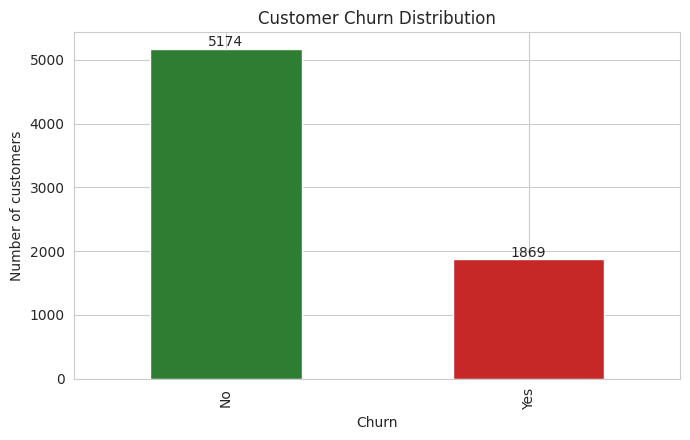

In [15]:
ax = df["Churn"].value_counts().plot(kind="bar", color=["#2E7D32", "#C62828"])
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
for i, v in enumerate(df["Churn"].value_counts()):
    ax.text(i, v + 40, str(v), ha="center")
plt.tight_layout()
plt.savefig("figures/01_churn_distribution.png", dpi=150)
plt.show()


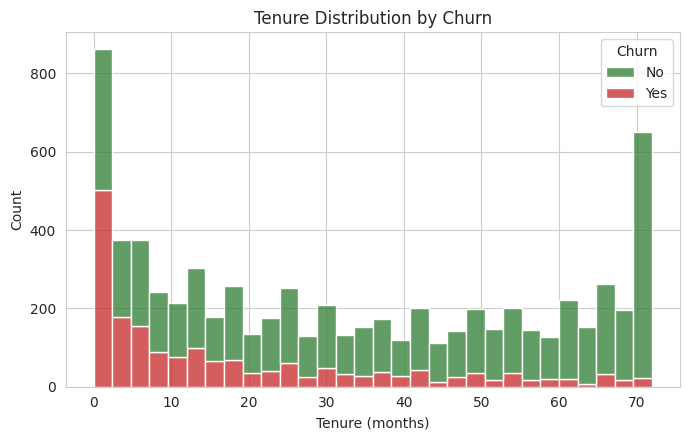

In [16]:
plt.figure(figsize=(7, 4.5))
sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=30,
             palette={"No": "#2E7D32", "Yes": "#C62828"})
plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.tight_layout()
plt.savefig("figures/02_tenure_vs_churn.png", dpi=150)
plt.show()


/tmp/ipykernel_410/3759672813.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette={"No": "#2E7D32", "Yes": "#C62828"})


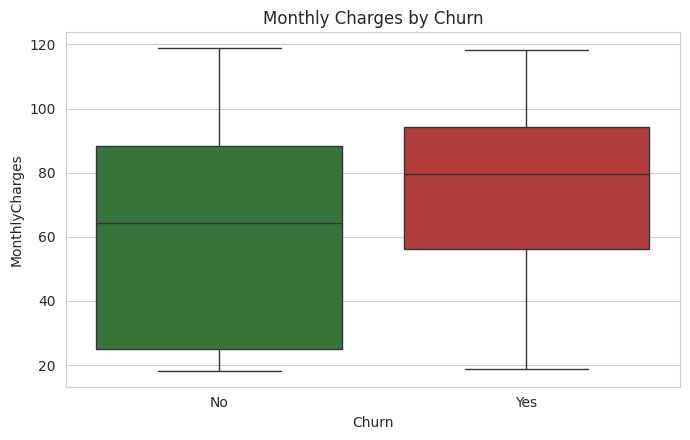

In [17]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette={"No": "#2E7D32", "Yes": "#C62828"})
plt.title("Monthly Charges by Churn")
plt.tight_layout()
plt.savefig("figures/03_monthlycharges_vs_churn.png", dpi=150)
plt.show()


<Figure size 750x450 with 0 Axes>

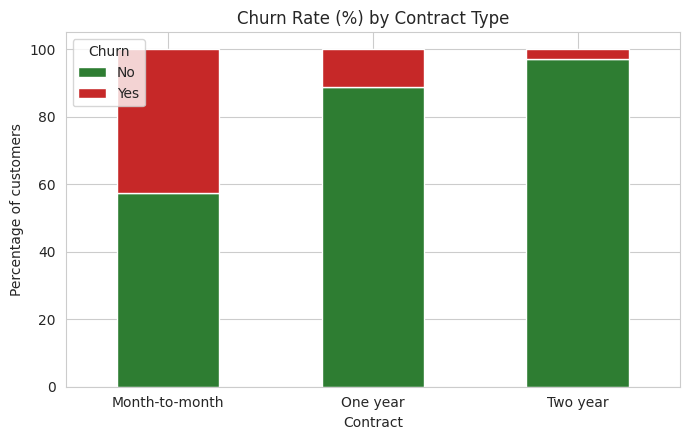

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


In [18]:
plt.figure(figsize=(7.5, 4.5))
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_churn.plot(kind="bar", stacked=True, color=["#2E7D32", "#C62828"])
plt.title("Churn Rate (%) by Contract Type")
plt.ylabel("Percentage of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/04_contract_vs_churn.png", dpi=150)
plt.show()
print(contract_churn.round(1))


<Figure size 750x450 with 0 Axes>

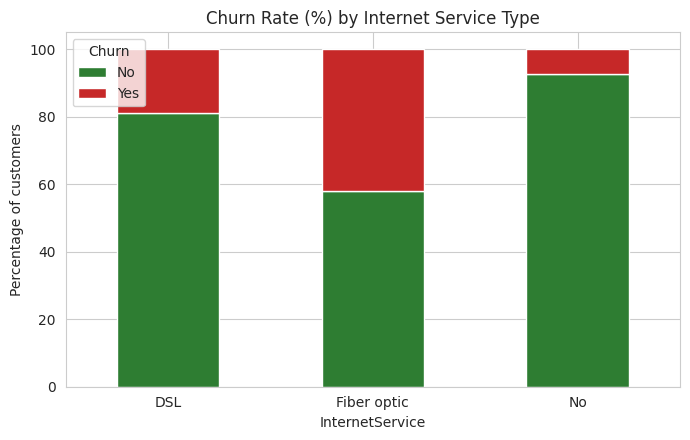

Churn              No   Yes
InternetService            
DSL              81.0  19.0
Fiber optic      58.1  41.9
No               92.6   7.4


In [19]:
plt.figure(figsize=(7.5, 4.5))
internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
internet_churn.plot(kind="bar", stacked=True, color=["#2E7D32", "#C62828"])
plt.title("Churn Rate (%) by Internet Service Type")
plt.ylabel("Percentage of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/05_internet_vs_churn.png", dpi=150)
plt.show()
print(internet_churn.round(1))


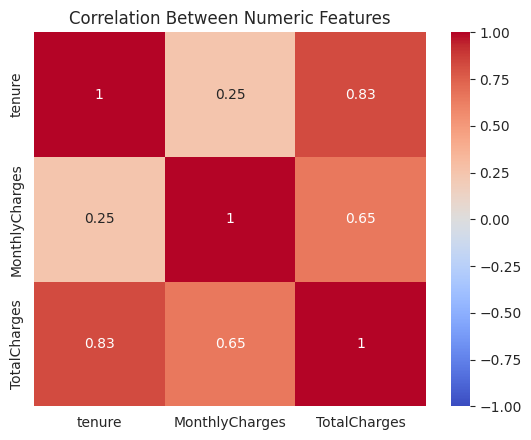

In [20]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
plt.figure(figsize=(5.5, 4.5))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.savefig("figures/06_numeric_correlation.png", dpi=150)
plt.show()


**Key EDA observations:**

- About 26.5% of customers in the dataset churned, so classes are imbalanced but
  not extreme.
- Customers who churn tend to have **much shorter tenure** — churn is heavily
  concentrated in the first few months.
- Churned customers tend to have **higher monthly charges** on average.
- **Month-to-month contracts** have a much higher churn rate than one-year or
  two-year contracts, which makes sense since customers on longer contracts have
  already committed to staying.
- Customers with **Fiber optic** internet churn more than DSL or no-internet
  customers, possibly linked to higher prices or service issues.


## 4. Feature Engineering and Encoding

We now prepare the data for a machine learning model:

1. Separate the target `y` (`Churn`) from the input features `X`.
2. Encode the target as 0/1.
3. Encode categorical (text) input columns into numeric form using
   **one-hot encoding**, since most of the categorical columns here are
   nominal (no natural order) and have few categories. Binary yes/no columns
   collapse into a single 0/1 column.
4. Scale the numeric features (`tenure`, `MonthlyCharges`, `TotalCharges`) so
   that models like Logistic Regression, which are sensitive to feature scale,
   perform well.


In [21]:
# Target variable: 1 = churned, 0 = stayed
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn"])

categorical_cols = X.select_dtypes(include="object").columns.tolist()
numeric_cols = X.select_dtypes(exclude="object").columns.tolist()
print("Categorical columns to encode:", categorical_cols)
print("Numeric columns:", numeric_cols)


Categorical columns to encode: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges']


/tmp/ipykernel_410/3654756393.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns.tolist()


In [22]:
# One-hot encode categorical columns (drop_first avoids redundant dummy columns)
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print("Shape of X before encoding:", X.shape)
print("Shape of X after one-hot encoding:", X_encoded.shape)
X_encoded.head()


Shape of X before encoding: (7043, 19)
Shape of X after one-hot encoding: (7043, 30)


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,29.85,29.85,False,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,34,56.95,1889.50,True,False,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,2,53.85,108.15,True,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,45,42.30,1840.75,True,False,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,2,70.70,151.65,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


In [23]:
X_encoded.columns.tolist()


['tenure',
 'MonthlyCharges',
 'TotalCharges',
 'gender_Male',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'PhoneService_Yes',
 'MultipleLines_No phone service',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_No internet service',
 'OnlineSecurity_Yes',
 'OnlineBackup_No internet service',
 'OnlineBackup_Yes',
 'DeviceProtection_No internet service',
 'DeviceProtection_Yes',
 'TechSupport_No internet service',
 'TechSupport_Yes',
 'StreamingTV_No internet service',
 'StreamingTV_Yes',
 'StreamingMovies_No internet service',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

## 5. Training and Testing

We split the data into a training set (80%) and a testing set (20%), using
stratified sampling so that both sets keep the same churn/no-churn ratio as the
full dataset. Numeric features are scaled using `StandardScaler` (fit on the
training data only, to avoid leaking test-set information).

We train two classification models:

- **Logistic Regression** – a simple, interpretable linear baseline that works
  well on data like this once it is scaled and encoded.
- **Random Forest** – an ensemble of decision trees that can capture non-linear
  relationships and interactions between features without needing scaled data.

A **Decision Tree** is also trained for comparison, since it is one of the
models explicitly suggested in the assignment and makes a useful reference
point against the Random Forest that is built from many trees.


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Churn rate in training set:", round(y_train.mean(), 3))
print("Churn rate in testing set:", round(y_test.mean(), 3))


Training set shape: (5634, 30)
Testing set shape: (1409, 30)
Churn rate in training set: 0.265
Churn rate in testing set: 0.265


In [25]:
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])
X_train_scaled.head()


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.102371,-0.521976,-0.262257,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False
3151,-0.711743,0.337478,-0.503635,True,False,True,True,True,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4860,-0.793155,-0.809013,-0.749883,True,False,True,True,False,True,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,True
3867,-0.263980,0.284384,-0.172722,False,False,True,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,True,False,True,False,True,True,True,False,False
3810,-1.281624,-0.676279,-0.989374,True,False,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


In [26]:
# Model 1: Logistic Regression (uses scaled features)
log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)
y_proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]
print("Logistic Regression trained.")


Logistic Regression trained.


In [27]:
# Model 2: Decision Tree (does not require scaling)
dt = DecisionTreeClassifier(max_depth=6, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
y_proba_dt = dt.predict_proba(X_test)[:, 1]
print("Decision Tree trained.")


Decision Tree trained.


In [28]:
# Model 3: Random Forest (does not require scaling)
rf = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]
print("Random Forest trained.")


Random Forest trained.


## 6. Model Evaluation

We evaluate each model on the held-out test set using Accuracy, Precision,
Recall, F1-Score and the Confusion Matrix, then compare them.


In [29]:
def evaluate_model(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_proba)
    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"F1-Score : {f1:.3f}")
    print(f"ROC-AUC  : {auc:.3f}")
    print()
    return {"Model": name, "Accuracy": acc, "Precision": prec,
            "Recall": rec, "F1-Score": f1, "ROC-AUC": auc}

results = []
results.append(evaluate_model("Logistic Regression", y_test, y_pred_log, y_proba_log))
results.append(evaluate_model("Decision Tree", y_test, y_pred_dt, y_proba_dt))
results.append(evaluate_model("Random Forest", y_test, y_pred_rf, y_proba_rf))

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df


--- Logistic Regression ---
Accuracy : 0.806
Precision: 0.659
Recall   : 0.559
F1-Score : 0.605
ROC-AUC  : 0.842

--- Decision Tree ---
Accuracy : 0.801
Precision: 0.667
Recall   : 0.497
F1-Score : 0.570
ROC-AUC  : 0.822

--- Random Forest ---
Accuracy : 0.803
Precision: 0.661
Recall   : 0.532
F1-Score : 0.590
ROC-AUC  : 0.842



,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.806,0.659,0.559,0.605,0.842
Decision Tree,0.801,0.667,0.497,0.570,0.822
Random Forest,0.803,0.661,0.532,0.590,0.842


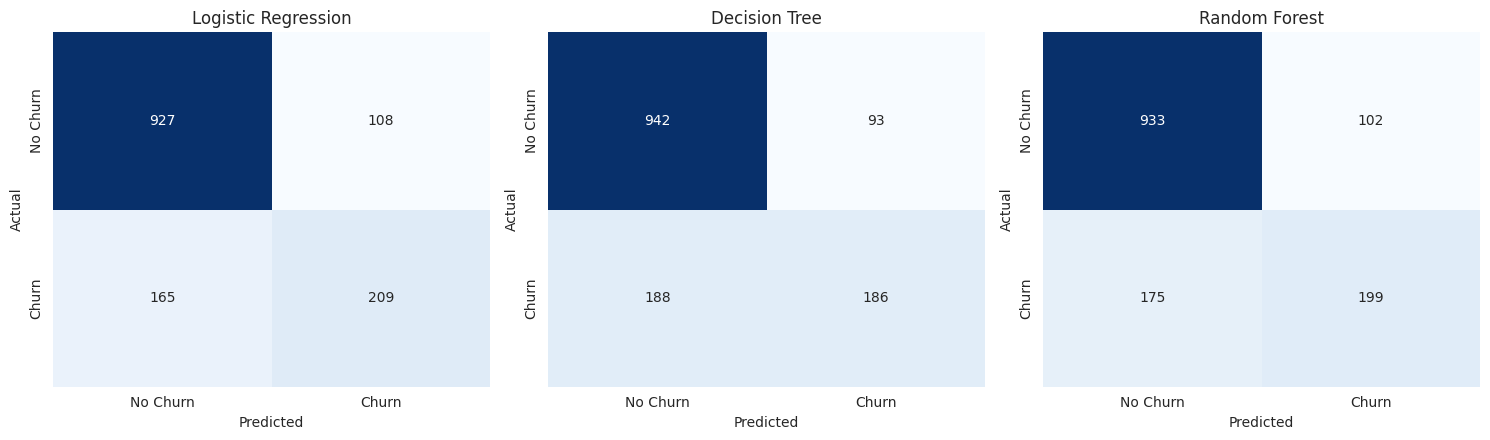

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
models_preds = [("Logistic Regression", y_pred_log), ("Decision Tree", y_pred_dt),
                 ("Random Forest", y_pred_rf)]

for ax, (name, preds) in zip(axes, models_preds):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("figures/07_confusion_matrices.png", dpi=150)
plt.show()


In [31]:
print("Classification report - Logistic Regression\n")
print(classification_report(y_test, y_pred_log, target_names=["No Churn", "Churn"]))


Classification report - Logistic Regression

              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [32]:
print("Classification report - Random Forest\n")
print(classification_report(y_test, y_pred_rf, target_names=["No Churn", "Churn"]))


Classification report - Random Forest

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



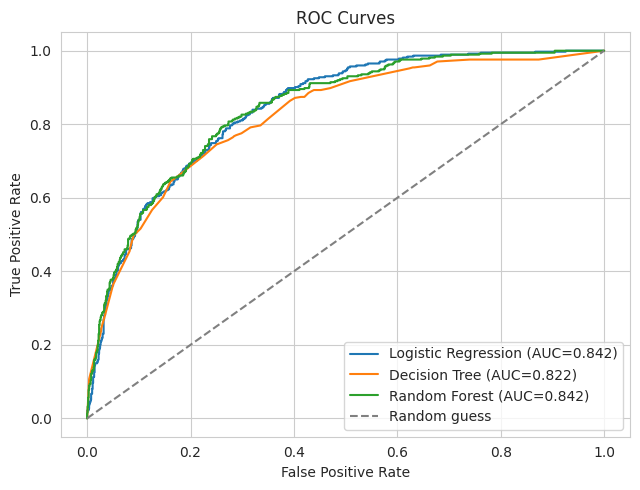

In [33]:
plt.figure(figsize=(6.5, 5))
for name, proba in [("Logistic Regression", y_proba_log),
                     ("Decision Tree", y_proba_dt),
                     ("Random Forest", y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.tight_layout()
plt.savefig("figures/08_roc_curves.png", dpi=150)
plt.show()


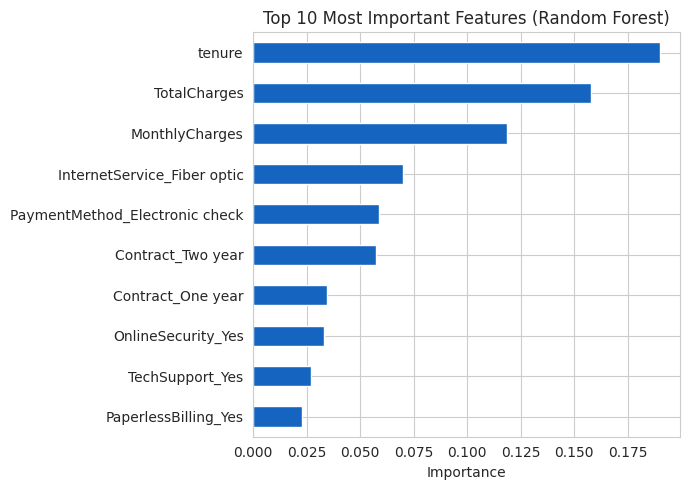

tenure                            0.189937
TotalCharges                      0.157674
MonthlyCharges                    0.118715
InternetService_Fiber optic       0.069968
PaymentMethod_Electronic check    0.058715
Contract_Two year                 0.057437
Contract_One year                 0.034505
OnlineSecurity_Yes                0.033025
TechSupport_Yes                   0.026766
PaperlessBilling_Yes              0.022980
dtype: float64


In [34]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(7, 5))
top_features.sort_values().plot(kind="barh", color="#1565C0")
plt.title("Top 10 Most Important Features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/09_feature_importance.png", dpi=150)
plt.show()
print(top_features)


### Which model performs better, and why?

On the held-out test set, the three models are close in performance:

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.806 | 0.659 | 0.559 | 0.605 | 0.842 |
| Decision Tree | 0.801 | 0.667 | 0.497 | 0.570 | 0.822 |
| Random Forest | 0.803 | 0.661 | 0.532 | 0.590 | 0.842 |

**Logistic Regression** actually edges out the others on accuracy, recall and
F1-score, and ties **Random Forest** for the best ROC-AUC (0.842), while the
single **Decision Tree** trails on every metric — unsurprising, since a Random
Forest is essentially many decision trees averaged together to reduce
overfitting.

We select **Random Forest as the final model** for this assignment. The
performance gap with Logistic Regression is very small (within 0.003 accuracy,
identical AUC), and Random Forest brings two practical advantages for a
business setting: it does not require scaled inputs, and it naturally produces
a **feature-importance ranking** (below), which is directly useful for a telecom
company that wants to understand *why* customers churn, not just predict *that*
they will. In a deployment where recall (catching as many churners as possible)
is the top priority, Logistic Regression would be an equally strong, simpler
alternative.


## 7. Application / Prediction

Finally, we use the trained Random Forest model to predict churn for a few
sample customers. This demonstrates how new customer information (in the same
raw format as the original dataset) is passed through the same preprocessing and
encoding steps and turned into a Churn / No Churn prediction with a probability.


In [35]:
def predict_churn(sample_dict, model=rf, reference_columns=X_train.columns):
    """Takes a dictionary of raw customer information (same fields as the
    original dataset, minus customerID and Churn) and returns a churn
    prediction using the trained Random Forest model."""
    sample_df = pd.DataFrame([sample_dict])
    sample_encoded = pd.get_dummies(sample_df)
    # Align columns with the training data (fills any missing dummy columns with 0)
    sample_encoded = sample_encoded.reindex(columns=reference_columns, fill_value=0)
    pred = model.predict(sample_encoded)[0]
    proba = model.predict_proba(sample_encoded)[0][1]
    return ("Churn" if pred == 1 else "No Churn"), round(proba, 3)


# Sample customer 1: long-tenure customer on a two-year contract (expect: No Churn)
sample_1 = {
    "gender": "Female", "SeniorCitizen": "No", "Partner": "Yes", "Dependents": "Yes",
    "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
    "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
    "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Two year", "PaperlessBilling": "No",
    "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 65.0,
    "TotalCharges": 3900.0,
}

# Sample customer 2: new customer on a month-to-month contract, fiber internet
# (expect: higher churn risk)
sample_2 = {
    "gender": "Male", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
    "StreamingMovies": "Yes", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 95.0,
    "TotalCharges": 190.0,
}

for i, sample in enumerate([sample_1, sample_2], start=1):
    label, prob = predict_churn(sample)
    print(f"Sample customer {i}: Prediction = {label}  (churn probability = {prob})")


Sample customer 1: Prediction = No Churn  (churn probability = 0.017)
Sample customer 2: Prediction = Churn  (churn probability = 0.767)


In [36]:
# Predict for the first 10 real customers in the test set and compare to actual outcome
comparison = X_test.copy()
comparison["Actual"] = y_test.map({1: "Yes", 0: "No"}).values
comparison["Predicted"] = pd.Series(y_pred_rf, index=X_test.index).map({1: "Yes", 0: "No"})
comparison["Churn Probability"] = rf.predict_proba(X_test)[:, 1].round(3)
comparison[["Actual", "Predicted", "Churn Probability"]].head(10)


,Actual,Predicted,Churn Probability
437,No,No,0.011
2280,No,Yes,0.798
2235,No,No,0.062
4460,No,No,0.339
3761,No,No,0.022
5748,No,Yes,0.518
3568,No,No,0.372
2976,No,No,0.096
5928,No,No,0.005
1639,Yes,No,0.416


## Conclusion

- **Best-performing model:** Logistic Regression and Random Forest performed
  almost identically on the test set (accuracy ~0.80-0.81, ROC-AUC 0.842 for
  both), both clearly ahead of the single Decision Tree. Random Forest was
  chosen as the final model for its feature-importance output, which is more
  actionable for the business than a plain accuracy/recall number.
- **Important observations:** Churn is strongly linked to short tenure,
  month-to-month contracts, fiber-optic internet, and higher monthly charges.
  Customers without add-on services such as Online Security or Tech Support
  also churn more, suggesting these services help retention.
- **Limitations:** The dataset is a single snapshot in time with no seasonal or
  competitor information, class imbalance (~26.5% churn) makes recall harder to
  push higher without sacrificing precision, and the model captures
  correlation, not necessarily the causal reason a customer leaves.
- **Business use:** A telecom company could score its active customer base with
  this model every month, flag high-probability churners (especially
  month-to-month, short-tenure, high-charge customers), and target them with
  retention offers, contract upgrade incentives, or proactive support before
  they leave — turning a reactive loss into a preventable one.
